
#  Week 8 Workshop

## Data Preprocessing and Analytics with Python and Pandas

# Dataset: Tyne Tunnel toll transactions for one individual

# Tools: Python, pandas, NumPy, SciPy, Matplotlib


In [11]:
# Importing all the tools needed for the analytics 

In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [109]:
# using pandas to import the dataset for analysis

In [18]:
 # veiwing dataset 
df

,type,transactionAmount,appliedAt,paymentRef,topUpType,balanceAfter,direction,vrm,toll,journeyTime,correctionContext
0,Journey,-2.16,2025-03-07 19:54:36,NaN,NaN,NaN,North,SP65XMG,2.16,2025-03-07 19:53:42,NaN
1,Journey,-2.16,2025-03-04 10:51:36,NaN,NaN,NaN,South,SP65XMG,2.16,2025-03-04 10:50:59,NaN
2,Journey,-2.16,2025-02-27 18:07:45,NaN,NaN,NaN,North,SP65XMG,2.16,2025-02-27 18:06:51,NaN
3,Journey,-2.16,2025-02-25 10:31:35,NaN,NaN,NaN,South,SP65XMG,2.16,2025-02-25 10:30:09,NaN
4,Journey,-2.16,2025-02-20 17:37:35,NaN,NaN,NaN,North,SP65XMG,2.16,2025-02-20 17:35:55,NaN
...,...,...,...,...,...,...,...,...,...,...,...
89,Top up,10.00,2024-03-22 09:16:42,pi_3Ox49uB6VsUpbUhX1Ep2GRcw,Manual,11.52,NaN,NaN,NaN,NaN,NaN
90,Journey,-1.98,2024-03-21 17:32:42,NaN,NaN,NaN,North,SP20ODX,1.98,2024-03-21 17:31:04,NaN
91,Journey,-1.98,2024-03-19 09:02:33,NaN,NaN,NaN,South,SP20ODX,1.98,2024-03-19 09:01:12,NaN
92,Journey,-1.98,2024-03-16 15:43:43,NaN,NaN,NaN,North,SP65XMG,1.98,2024-03-16 15:41:56,NaN


In [20]:
# generic discription of the data set 
df.describe()

,transactionAmount,balanceAfter,toll,correctionContext
count,94.000000,15.000000,79.000000,0.0
mean,-0.084468,11.806667,2.125823,NaN
std,4.815671,2.595333,0.071047,NaN
min,-2.160000,10.060000,1.980000,NaN
25%,-2.160000,10.740000,2.160000,NaN
50%,-2.160000,11.420000,2.160000,NaN
75%,-1.980000,11.690000,2.160000,NaN
max,20.000000,20.940000,2.160000,NaN


In [23]:
#basic information about the dataset 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   type               94 non-null     str    
 1   transactionAmount  94 non-null     float64
 2   appliedAt          94 non-null     str    
 3   paymentRef         15 non-null     str    
 4   topUpType          15 non-null     str    
 5   balanceAfter       15 non-null     float64
 6   direction          79 non-null     str    
 7   vrm                79 non-null     str    
 8   toll               79 non-null     float64
 9   journeyTime        79 non-null     str    
 10  correctionContext  0 non-null      float64
dtypes: float64(4), str(7)
memory usage: 13.5 KB


In [25]:
# The number of missing values in each column 
df.isnull().sum()

type                  0
transactionAmount     0
appliedAt             0
paymentRef           79
topUpType            79
balanceAfter         79
direction            15
vrm                  15
toll                 15
journeyTime          15
correctionContext    94
dtype: int64

In [28]:
#the percentage of missing missing value in each column 
(df.isnull().sum() / len(df)) * 100

type                   0.000000
transactionAmount      0.000000
appliedAt              0.000000
paymentRef            84.042553
topUpType             84.042553
balanceAfter          84.042553
direction             15.957447
vrm                   15.957447
toll                  15.957447
journeyTime           15.957447
correctionContext    100.000000
dtype: float64

In [31]:
#viewing the whole dataset 
print(df.to_string())

       type  transactionAmount            appliedAt                   paymentRef topUpType  balanceAfter direction      vrm  toll          journeyTime  correctionContext
0   Journey              -2.16  2025-03-07 19:54:36                          NaN       NaN           NaN     North  SP65XMG  2.16  2025-03-07 19:53:42                NaN
1   Journey              -2.16  2025-03-04 10:51:36                          NaN       NaN           NaN     South  SP65XMG  2.16  2025-03-04 10:50:59                NaN
2   Journey              -2.16  2025-02-27 18:07:45                          NaN       NaN           NaN     North  SP65XMG  2.16  2025-02-27 18:06:51                NaN
3   Journey              -2.16  2025-02-25 10:31:35                          NaN       NaN           NaN     South  SP65XMG  2.16  2025-02-25 10:30:09                NaN
4   Journey              -2.16  2025-02-20 17:37:35                          NaN       NaN           NaN     North  SP65XMG  2.16  2025-02-20 17:35:55

In [35]:
print(df['vrm'].value_counts())

vrm
SP65XMG    44
SP20ODX    35
Name: count, dtype: int64


In [37]:
print(df['type'].value_counts())

type
Journey    79
Top up     15
Name: count, dtype: int64


### Information Derived from the Dataset

# 1. The dataset contains two types of transactions: **Journey** and **Top Up**.

# 2. Negative values in the `transactionAmount` column represent toll charges associated with journeys.

# 3. A **Top Up** transaction occurs when the individual adds money to their account. It does not represent a journey or travel activity.

# 4. The dataset contains two vehicles, identified by their Vehicle Registration Marks (VRMs):
   - **SP65XMG:** 44 journeys.
   - **SP20ODX:** 35 journeys.

# 5. The recorded journey directions are either **North** or **South**.

# 6. The `correctionContext` column contains 100% missing values (null values), meaning that no information is recorded in this column.

## Data processing 

In [44]:
#creating a copy of the dataset for analysis
# We can keep the original and work on the copied one
df_copy = df.copy()

In [45]:
df_copy

,type,transactionAmount,appliedAt,paymentRef,topUpType,balanceAfter,direction,vrm,toll,journeyTime,correctionContext
0,Journey,-2.16,2025-03-07 19:54:36,NaN,NaN,NaN,North,SP65XMG,2.16,2025-03-07 19:53:42,NaN
1,Journey,-2.16,2025-03-04 10:51:36,NaN,NaN,NaN,South,SP65XMG,2.16,2025-03-04 10:50:59,NaN
2,Journey,-2.16,2025-02-27 18:07:45,NaN,NaN,NaN,North,SP65XMG,2.16,2025-02-27 18:06:51,NaN
3,Journey,-2.16,2025-02-25 10:31:35,NaN,NaN,NaN,South,SP65XMG,2.16,2025-02-25 10:30:09,NaN
4,Journey,-2.16,2025-02-20 17:37:35,NaN,NaN,NaN,North,SP65XMG,2.16,2025-02-20 17:35:55,NaN
...,...,...,...,...,...,...,...,...,...,...,...
89,Top up,10.00,2024-03-22 09:16:42,pi_3Ox49uB6VsUpbUhX1Ep2GRcw,Manual,11.52,NaN,NaN,NaN,NaN,NaN
90,Journey,-1.98,2024-03-21 17:32:42,NaN,NaN,NaN,North,SP20ODX,1.98,2024-03-21 17:31:04,NaN
91,Journey,-1.98,2024-03-19 09:02:33,NaN,NaN,NaN,South,SP20ODX,1.98,2024-03-19 09:01:12,NaN
92,Journey,-1.98,2024-03-16 15:43:43,NaN,NaN,NaN,North,SP65XMG,1.98,2024-03-16 15:41:56,NaN


In [48]:
df =  df_copy.copy()

In [49]:
df

,type,transactionAmount,appliedAt,paymentRef,topUpType,balanceAfter,direction,vrm,toll,journeyTime,correctionContext
0,Journey,-2.16,2025-03-07 19:54:36,NaN,NaN,NaN,North,SP65XMG,2.16,2025-03-07 19:53:42,NaN
1,Journey,-2.16,2025-03-04 10:51:36,NaN,NaN,NaN,South,SP65XMG,2.16,2025-03-04 10:50:59,NaN
2,Journey,-2.16,2025-02-27 18:07:45,NaN,NaN,NaN,North,SP65XMG,2.16,2025-02-27 18:06:51,NaN
3,Journey,-2.16,2025-02-25 10:31:35,NaN,NaN,NaN,South,SP65XMG,2.16,2025-02-25 10:30:09,NaN
4,Journey,-2.16,2025-02-20 17:37:35,NaN,NaN,NaN,North,SP65XMG,2.16,2025-02-20 17:35:55,NaN
...,...,...,...,...,...,...,...,...,...,...,...
89,Top up,10.00,2024-03-22 09:16:42,pi_3Ox49uB6VsUpbUhX1Ep2GRcw,Manual,11.52,NaN,NaN,NaN,NaN,NaN
90,Journey,-1.98,2024-03-21 17:32:42,NaN,NaN,NaN,North,SP20ODX,1.98,2024-03-21 17:31:04,NaN
91,Journey,-1.98,2024-03-19 09:02:33,NaN,NaN,NaN,South,SP20ODX,1.98,2024-03-19 09:01:12,NaN
92,Journey,-1.98,2024-03-16 15:43:43,NaN,NaN,NaN,North,SP65XMG,1.98,2024-03-16 15:41:56,NaN


In [50]:
#checking for duplicates
df.duplicated().sum()

np.int64(0)

Following a review of the dataset, the `correctionContext` column was removed because it contains 100% missing values and therefore provides no meaningful information for the analysis. Removing this column improves data quality and ensures the dataset retains only variables relevant to the analytical objectives.

In [52]:
df = df.drop(columns=['correctionContext'])

In [53]:
df.head()

,type,transactionAmount,appliedAt,paymentRef,topUpType,balanceAfter,direction,vrm,toll,journeyTime
0,Journey,-2.16,2025-03-07 19:54:36,NaN,NaN,NaN,North,SP65XMG,2.16,2025-03-07 19:53:42
1,Journey,-2.16,2025-03-04 10:51:36,NaN,NaN,NaN,South,SP65XMG,2.16,2025-03-04 10:50:59
2,Journey,-2.16,2025-02-27 18:07:45,NaN,NaN,NaN,North,SP65XMG,2.16,2025-02-27 18:06:51
3,Journey,-2.16,2025-02-25 10:31:35,NaN,NaN,NaN,South,SP65XMG,2.16,2025-02-25 10:30:09
4,Journey,-2.16,2025-02-20 17:37:35,NaN,NaN,NaN,North,SP65XMG,2.16,2025-02-20 17:35:55


In [54]:
df[["appliedAt", "journeyTime"]].dtypes

appliedAt      str
journeyTime    str
dtype: object

In [56]:
#Checking thr missing or invalid date-time values
df[["appliedAt", "journeyTime"]].isnull().sum()

appliedAt       0
journeyTime    15
dtype: int64

## The 15 missing values actually correspond to the 15 times the individual Top up 


In [57]:
#  Date-time conversion

df["appliedAt"] = pd.to_datetime(
    df["appliedAt"], errors="coerce"
)

df["journeyTime"] = pd.to_datetime(
    df["journeyTime"], errors="coerce"
)

In [58]:
#  anonymise vehicle registration -> Vehicle A, B
labels = {v: f"Vehicle {c}" for v, c in zip(df["vrm"].dropna().unique(), "ABCDEFGH")}
df["vehicle"] = df["vrm"].map(labels)
df = df.drop(columns="vrm")

In [59]:
print("Vehicle Classification:")
print(df['vehicle'].value_counts())

Vehicle Classification:
vehicle
Vehicle A    44
Vehicle B    35
Name: count, dtype: int64


## What we have done now is to classify the two vehicles as A and B instead of using their VRN label 

# To check the financial consistency 
### Negative values in the transactionAmount column represent toll charges associated with journeys; whether the statement is true or false 

In [62]:
j_mask = df["type"] == "Journey"
mismatch = (df.loc[j_mask, "transactionAmount"] + df.loc[j_mask, "toll"]).abs() > 1e-9
print("Journeys where charge != -toll:", int(mismatch.sum()))
print("Journeys with positive amount:", int((df.loc[j_mask, "transactionAmount"] > 0).sum()))
print("Top-ups with non-positive amount:",
      int((df.loc[df.type == "Top up", "transactionAmount"] <= 0).sum()))

Journeys where charge != -toll: 0
Journeys with positive amount: 0
Top-ups with non-positive amount: 0


The statement is true; hence, every journey charge equals the negative of its toll, so the financial values are consistent

In [63]:
#  Derived variables
# Calculating time in hours between the journey and when the charge was applied

df["posting_delay_hours"] = (df["appliedAt"] - df["journeyTime"]).dt.total_seconds() / 3600

# Classify each transaction as either a toll charge or an account top-up
df["category"] = np.where(df["type"] == "Journey", "Toll charge", "Account top-up")

In [67]:
# Quick look at the new columns
print(df[["appliedAt", "journeyTime", "posting_delay_hours", "type", "category"]].head(5))

            appliedAt         journeyTime  posting_delay_hours     type  \
0 2025-03-07 19:54:36 2025-03-07 19:53:42             0.015000  Journey   
1 2025-03-04 10:51:36 2025-03-04 10:50:59             0.010278  Journey   
2 2025-02-27 18:07:45 2025-02-27 18:06:51             0.015000  Journey   
3 2025-02-25 10:31:35 2025-02-25 10:30:09             0.023889  Journey   
4 2025-02-20 17:37:35 2025-02-20 17:35:55             0.027778  Journey   

      category  
0  Toll charge  
1  Toll charge  
2  Toll charge  
3  Toll charge  
4  Toll charge  


## . Splitting into Journeys and Top-ups

Create two clean DataFrames:
- `j` → journeys with time-based features
- `t` → top-ups with month grouping

In [68]:
 #Split into journeys and top-ups
j = df[j_mask].copy().sort_values("journeyTime")
j["spend"] = -j["transactionAmount"]
j["date"] = j["journeyTime"].dt.normalize()
j["month"] = j["journeyTime"].dt.to_period("M")
j["weekday"] = j["journeyTime"].dt.day_name()
j["is_weekend"] = j["journeyTime"].dt.dayofweek >= 5
j["hour"] = j["journeyTime"].dt.hour
j["days_since_last"] = j["journeyTime"].diff().dt.days

t = df[df["type"] == "Top up"].copy().sort_values("appliedAt")
t["month"] = t["appliedAt"].dt.to_period("M")

In [69]:
# Check top-ups DataFrame
print("\n=== Top-ups (t) ===")
print(t[["appliedAt", "transactionAmount", "month"]].head(10))
print(f"\nShape: {t.shape}")
print(f"\nMonth counts:\n{t['month'].value_counts().sort_index()}")


=== Top-ups (t) ===
             appliedAt  transactionAmount    month
89 2024-03-22 09:16:42               10.0  2024-03
83 2024-04-11 13:36:05               10.0  2024-04
77 2024-04-25 20:30:56               10.0  2024-04
71 2024-05-14 10:11:18               10.0  2024-05
65 2024-05-24 14:53:43               10.0  2024-05
60 2024-06-20 22:45:34               10.0  2024-06
54 2024-08-16 19:46:30               10.0  2024-08
48 2024-09-12 19:23:03               10.0  2024-09
43 2024-09-24 14:17:45               10.0  2024-09
37 2024-10-27 23:13:22               10.0  2024-10

Shape: (15, 13)

Month counts:
month
2024-03    1
2024-04    2
2024-05    2
2024-06    1
2024-08    1
2024-09    2
2024-10    1
2024-11    1
2024-12    1
2025-01    2
2025-02    1
Freq: M, Name: count, dtype: int64


##  Posting Delay Outliers

 To detect journeys with unusually long delays between the journey and when the charge was applied, and to summarise the results.

In [71]:
# outliers in posting delay 
q1, q3 = j["posting_delay_hours"].quantile([.25, .75])
out = j[j["posting_delay_hours"] > q3 + 1.5 * (q3 - q1)]
print(f"Posting-delay outliers: {len(out)} journeys (max {j['posting_delay_hours'].max():.1f} hours)")
print(f"Cleaned journeys: {len(j)} | top-ups: {len(t)}")
j[["journeyTime", "direction", "vehicle", "spend", "month", "weekday", "hour"]].head()

Posting-delay outliers: 9 journeys (max 109.1 hours)
Cleaned journeys: 79 | top-ups: 15


,journeyTime,direction,vehicle,spend,month,weekday,hour
93,2024-03-12 09:00:27,South,Vehicle A,1.98,2024-03,Tuesday,9
92,2024-03-16 15:41:56,North,Vehicle A,1.98,2024-03,Saturday,15
91,2024-03-19 09:01:12,South,Vehicle B,1.98,2024-03,Tuesday,9
90,2024-03-21 17:31:04,North,Vehicle B,1.98,2024-03,Thursday,17
88,2024-03-26 10:06:42,South,Vehicle B,1.98,2024-03,Tuesday,10


#  Exploratory data analysis and statistical investigation
##  Descriptive analytics
### . How does usage vary across months, days of the week, and hours of the day?

In [74]:
#monthly trips 
monthly_trips_named = monthly_trips.copy()
monthly_trips_named.index = monthly_trips_named.index.strftime("%B %Y")

print("Trips per month:\n", monthly_trips_named)

Trips per month:
 March 2024         6
April 2024         9
May 2024          11
June 2024          4
July 2024          2
August 2024        3
September 2024     8
October 2024       6
November 2024      8
December 2024      4
January 2025       8
February 2025      8
March 2025         2
dtype: int64


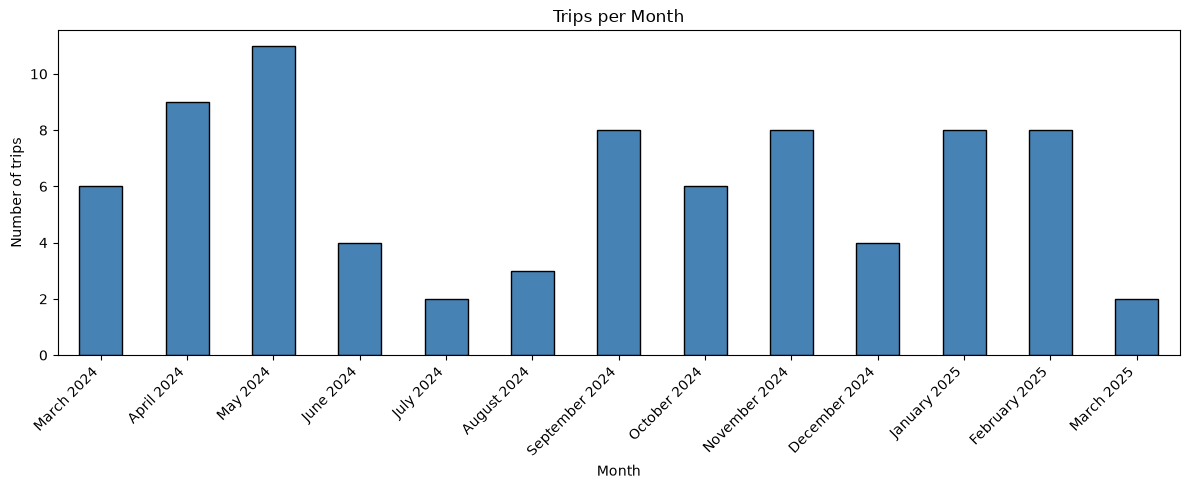

In [75]:
plt.figure(figsize=(12, 5))
monthly_trips_named.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Trips per Month")
plt.xlabel("Month")
plt.ylabel("Number of trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Months:** busiest in May 2024 (11 trips); quietest in July 2024 and March 2025 (2 trips each)

In [76]:
#weekdays trips 
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = j["weekday"].value_counts().reindex(order, fill_value=0)

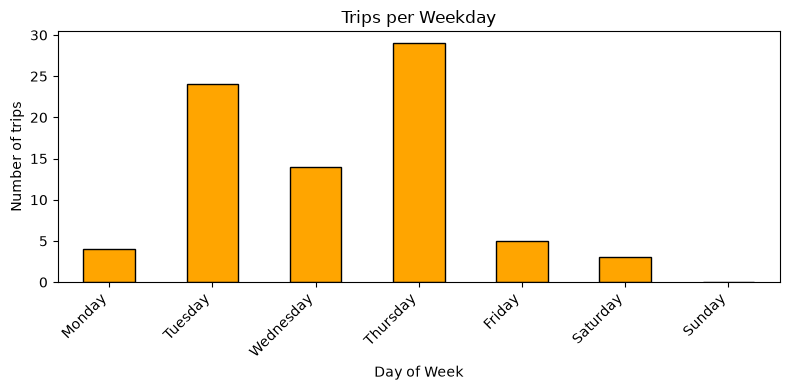

In [78]:
plt.figure(figsize=(8, 4))
by_day.plot(kind="bar", color="orange", edgecolor="black")
plt.title("Trips per Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Number of trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Weekdays:** Tuesday (24) and Thursday (29). Sunday has none.

In [79]:
by_hour = j["hour"].value_counts().sort_index().reindex(range(24), fill_value=0)

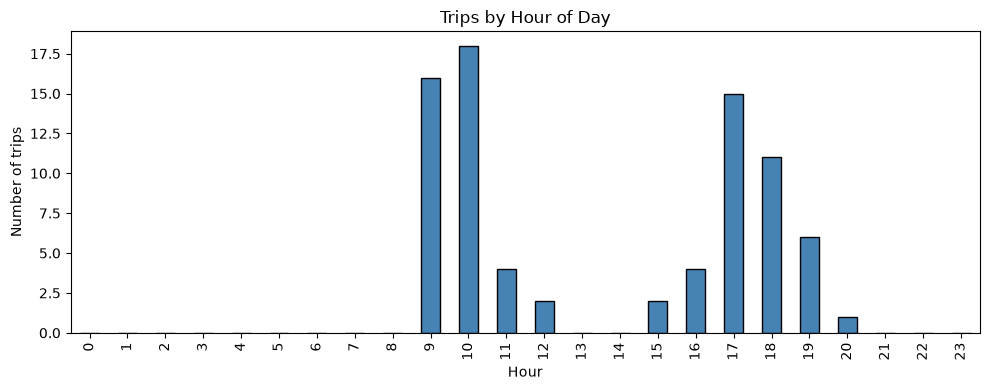

In [80]:
plt.figure(figsize=(10, 4))
by_hour.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Trips by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of trips")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

# For better understanding, we are grouping it into morning, afternoon, and night 

In [85]:
# Define the groups
def time_of_day(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    else:
        return "Night"

# Apply the grouping
j["time_of_day"] = j["hour"].apply(time_of_day)

# Order and count
order = ["Morning", "Afternoon", "Night"]
by_period = j["time_of_day"].value_counts().reindex(order, fill_value=0)

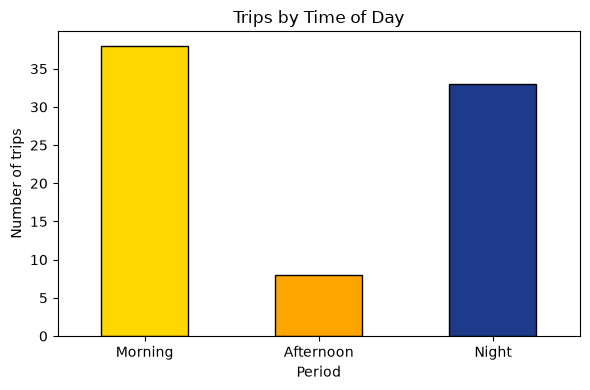

time_of_day
Morning      38
Afternoon     8
Night        33
Name: count, dtype: int64


In [83]:
# Plot
plt.figure(figsize=(6, 4))
by_period.plot(kind="bar", color=["#FFD700", "#FFA500", "#1E3A8A"], edgecolor="black")
plt.title("Trips by Time of Day")
plt.xlabel("Period")
plt.ylabel("Number of trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(by_period)

**Hours:** two clear peaks, around 9-10am and 5-6pm.

### . Patterns in monthly expenditure, average toll charge, and top-ups

In [90]:
monthly = pd.DataFrame({
    "trips": monthly_trips,
    "spend": j.groupby("month")["spend"].sum().reindex(all_months, fill_value=0),
    "avg_toll": j.groupby("month")["spend"].mean().reindex(all_months),
    "topup_total": t.groupby("month")["transactionAmount"].sum().reindex(all_months, fill_value=0),
    "topup_count": t.groupby("month").size().reindex(all_months, fill_value=0),
})
# Rename the index to full month names
monthly.index = monthly.index.strftime("%B %Y")

In [91]:
print(monthly.round(2))

                trips  spend  avg_toll  topup_total  topup_count
March 2024          6  11.88      1.98         10.0            1
April 2024          9  17.82      1.98         20.0            2
May 2024           11  23.76      2.16         20.0            2
June 2024           4   8.64      2.16         10.0            1
July 2024           2   4.32      2.16          0.0            0
August 2024         3   6.48      2.16         10.0            1
September 2024      8  17.28      2.16         20.0            2
October 2024        6  12.96      2.16         10.0            1
November 2024       8  17.28      2.16         10.0            1
December 2024       4   8.64      2.16         10.0            1
January 2025        8  17.28      2.16         20.0            2
February 2025       8  17.28      2.16         20.0            1
March 2025          2   4.32      2.16          0.0            0


In [92]:
print(f"\nTotal spend £{j.spend.sum():.2f} vs total top-ups £{t.transactionAmount.sum():.2f}")


Total spend £167.94 vs total top-ups £160.00


In [95]:
toll_periods = j.groupby("spend")["journeyTime"].agg(["count", "min", "max"])

toll_periods["min"] = toll_periods["min"].dt.strftime("%B %Y")
toll_periods["max"] = toll_periods["max"].dt.strftime("%B %Y")

print("\nToll rate periods:\n", toll_periods)


Toll rate periods:
        count         min         max
spend                               
1.98      15  March 2024  April 2024
2.16      64    May 2024  March 2025


# Monthly spending ranges from about £4 to £24 and follows the number of trips
 
 # The toll per trip **rose from £1.98 to £2.16** around 1 May 2024 and stayed there.

###  Differences between directions of travel

In [97]:
d = j.groupby("direction").agg(
    trips=("spend", "size"),
    mean_hour=("hour", "mean"),
    std_hour=("hour", "std"),
    min_hour=("hour", "min"),
    max_hour=("hour", "max"),
    total_spend=("spend", "sum")
)
print(d.round(2))

           trips  mean_hour  std_hour  min_hour  max_hour  total_spend
direction                                                             
North         38      17.47      1.13        15        20        80.82
South         41       9.98      1.39         9        17        87.12


**South** trips happen mostly in the **morning** (mean hour about 10:00); **North** trips mostly in the **evening** (mean hour about 17:30).


In [102]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Create crosstab and force the correct column order
direction_weekday = pd.crosstab(j["direction"], j["weekday"])
direction_weekday = direction_weekday.reindex(columns=order, fill_value=0)

print("\nDirection x weekday:\n", direction_weekday)


Direction x weekday:
 weekday    Monday  Tuesday  Wednesday  Thursday  Friday  Saturday  Sunday
direction                                                                
North           0        0          5        28       3         2       0
South           4       24          9         1       2         1       0


In [110]:
import seaborn as sns

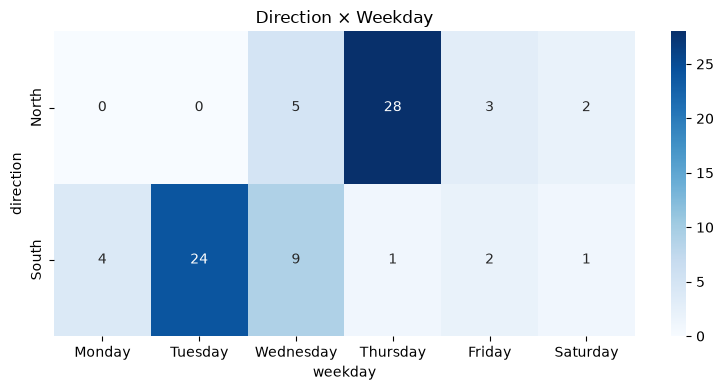

In [115]:


ct_weekday = pd.crosstab(j["direction"], j["weekday"])[[c for c in order if c in j["weekday"].unique()]]

plt.figure(figsize=(8, 4))
sns.heatmap(ct_weekday, annot=True, fmt="d", cmap="Blues")
plt.title("Direction × Weekday")
plt.tight_layout()
plt.show()

 South trips fall mainly on **Tuesdays** (24 of 41) and North trips on **Thursdays** (28 of 38), a Tuesday-out, Thursday-back pattern.

In [104]:
ct = pd.crosstab(j["direction"], j["vehicle"])
print("\nDirection x vehicle:\n", ct)
chi = stats.chi2_contingency(ct)
print(f"Chi-square direction vs vehicle: chi2={chi[0]:.2f}, p={chi[1]:.3f}")


Direction x vehicle:
 vehicle    Vehicle A  Vehicle B
direction                      
North             22         16
South             22         19
Chi-square direction vs vehicle: chi2=0.02, p=0.879


 The chi-square p = 0.88: hence, Direction is **not** associated with which vehicle was used 

### Consistency of Tunnel usage over time

In [117]:
#Week trips
weekly = j.set_index("journeyTime").resample("W").size()

In [119]:
#summary of statistics for both month and weeks 
for name, s in [("Monthly trips", monthly_trips), ("Weekly trips", weekly)]:
    print(f"{name}: mean={s.mean():.2f}, std={s.std():.2f}, CV={s.std()/s.mean():.2f}, "
          f"IQR={s.quantile(.75)-s.quantile(.25):.1f}, min={s.min()}, max={s.max()}")

Monthly trips: mean=6.08, std=2.87, CV=0.47, IQR=4.0, min=2, max=11
Weekly trips: mean=1.52, std=0.94, CV=0.62, IQR=1.2, min=0, max=4


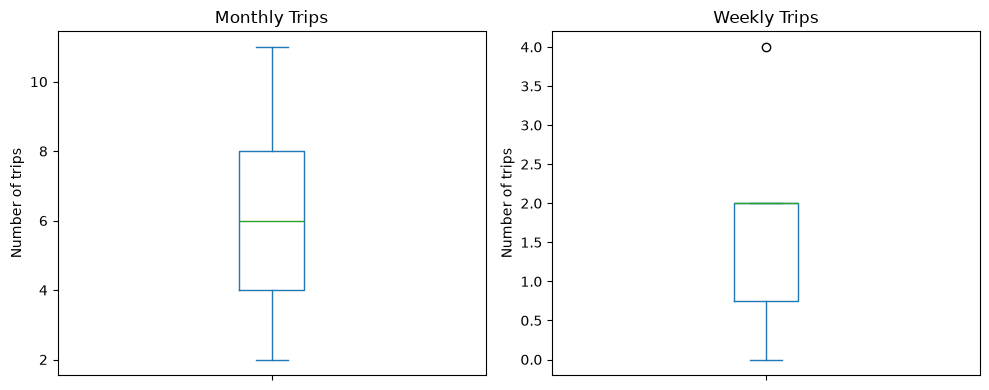

In [126]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

monthly_trips.plot(kind="box", ax=axes[0])
axes[0].set_title("Monthly Trips")
axes[0].set_ylabel("Number of trips")

weekly.plot(kind="box", ax=axes[1])
axes[1].set_title("Weekly Trips")
axes[1].set_ylabel("Number of trips")

plt.tight_layout()
plt.show()

In [121]:
#Days between trips 

g = j["days_since_last"].dropna()
print(f"Days between trips: mean={g.mean():.2f}, median={g.median():.1f}, "
      f"std={g.std():.2f}, CV={g.std()/g.mean():.2f}, max={g.max():.0f}")

Days between trips: mean=4.12, median=3.0, std=5.37, CV=1.30, max=36


In [123]:
#weeks with no trips 
print(f"Weeks with zero trips: {(weekly == 0).sum()} of {len(weekly)}")

Weeks with zero trips: 13 of 52


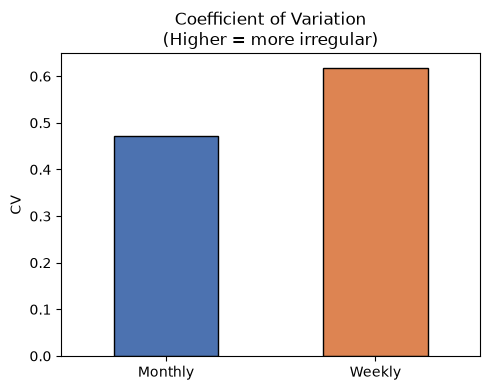

In [127]:
cv_data = pd.Series({
    "Monthly": monthly_trips.std() / monthly_trips.mean(),
    "Weekly": weekly.std() / weekly.mean()
})

plt.figure(figsize=(5, 4))
cv_data.plot(kind="bar", color=["#4C72B0", "#DD8452"], edgecolor="black")
plt.title("Coefficient of Variation\n(Higher = more irregular)")
plt.ylabel("CV")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Measures of variability used:** standard deviation, interquartile range (IQR), and the **coefficient of variation (CV = std/mean)**, which allows variability to be compared across measures with different scales.

 Monthly trips have a CV of about 0.47 and weekly trips about 0.62, which is variability. The gap between trips has a CV of about 1.3 (mostly short gaps with a few long ones, up to 36 days). About 13 of 52 weeks had no trips. Usage is therefore regular in its weekly pattern but not constant across the year.

## Statistical investigation

###  Do weekday and weekend journey frequencies differ?
**Method:** Build a daily count series covering every calendar day (including days with zero trips), then compare weekdays and weekends with a **Mann-Whitney U test**.

**Why:** Daily counts are discrete and heavily skewed, so they are not normally distributed and a t-test would be inappropriate.

In [130]:
#daily trips
days = pd.date_range(j["date"].min(), j["date"].max(), freq="D")
daily = j.groupby("date").size().reindex(days, fill_value=0)
daily_df = pd.DataFrame({"trips": daily, "weekend": daily.index.dayofweek >= 5})

In [131]:
print(daily_df.groupby("weekend")["trips"].agg(["count", "sum", "mean", "std"]).round(3))

         count  sum   mean    std
weekend                          
False      259   76  0.293  0.473
True       102    3  0.029  0.170


In [132]:
#Mann-Whitney U test
wk = daily_df.loc[~daily_df.weekend, "trips"]
we = daily_df.loc[daily_df.weekend, "trips"]
u = stats.mannwhitneyu(wk, we, alternative="two-sided")
print(f"\nMann-Whitney U: U={u.statistic:.0f}, p={u.pvalue:.2e}")


Mann-Whitney U: U=16598, p=9.04e-08


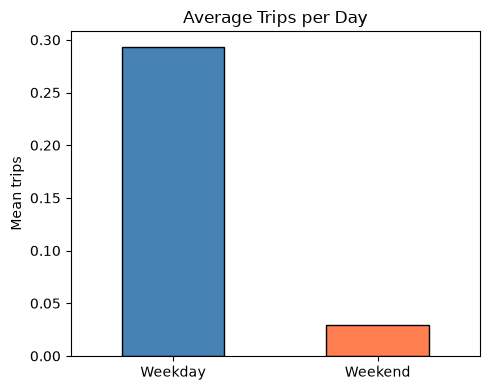

In [137]:


summary = daily_df.groupby("weekend")["trips"].mean()
summary.index = ["Weekday", "Weekend"]

plt.figure(figsize=(5, 4))
summary.plot(kind="bar", color=["steelblue", "coral"], edgecolor="black")
plt.title("Average Trips per Day")
plt.ylabel("Mean trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

 ## Weekdays average about 0.29 trips per day, compared with about 0.03 on weekends (only 3 weekend trips in the whole period). 
 ## The difference is **statistically significant** (p < 0.001), so tunnel use is overwhelmingly a weekday activity.

###  Is journey frequency associated with monthly expenditure?
**Method:** Using Pearson (linear) and Spearman (rank) correlations between monthly trips and monthly spending.

In [138]:
# Checking the relationship between the number of trips and the total spend each month.
pr = stats.pearsonr(monthly["trips"], monthly["spend"])
sr = stats.spearmanr(monthly["trips"], monthly["spend"])
print(f"Pearson r={pr[0]:.3f} (p={pr[1]:.2e}); Spearman rho={sr[0]:.3f} (p={sr[1]:.2e})")

Pearson r=0.997 (p=2.76e-13); Spearman rho=0.999 (p=2.32e-15)


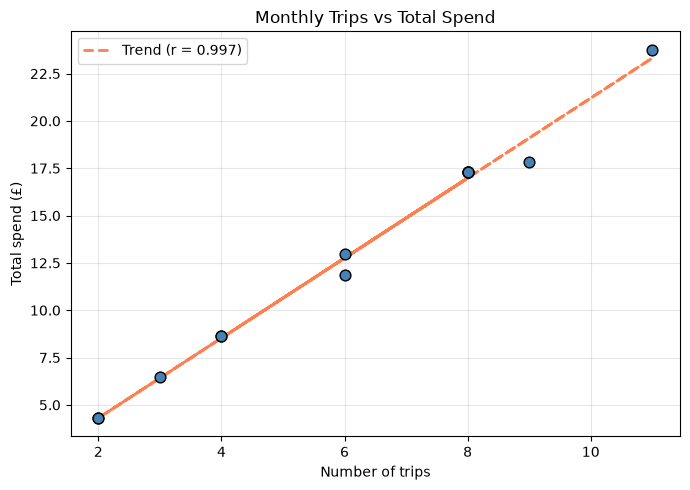

In [139]:


plt.figure(figsize=(7, 5))

# Scatter plot
plt.scatter(monthly["trips"], monthly["spend"], color="steelblue", s=60, edgecolor="black", zorder=3)

# Trend line
z = np.polyfit(monthly["trips"], monthly["spend"], 1)
p = np.poly1d(z)
plt.plot(monthly["trips"], p(monthly["trips"]), color="coral", linestyle="--", linewidth=2, label=f"Trend (r = 0.997)")

plt.title("Monthly Trips vs Total Spend")
plt.xlabel("Number of trips")
plt.ylabel("Total spend (£)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Months with more journeys have almost exactly proportional higher total spending. 
## The average toll amount is very consistent with the money spent, which is driven almost entirely by the number of trips.

---
## Limitations and conclusion
### Limitations of the data
- **One individual, about 12 months, 79 journeys:** the results describe this person only and do not generalise.
- **Small monthly samples** (2 to 11 trips) give statistical tests low power.
- **Only toll-paying crossings** are recorded; trips by other routes or methods are invisible.
- **Expenditure is fixed by the tariff**, so it adds little information beyond trip count.
- **Direction is the only location data**; there is no origin, destination, or trip purpose.
- **Two vehicles** are mixed, and one stops appearing after October 2024.

### Conclusion
Tunnel use is concentrated on **weekdays**, especially a **Tuesday morning (South) and Thursday Evening (North)** pattern. Usage has moderate month-to-month variability with quieter summer periods. Spending tracks trip count, with a single 9.1% toll increase in May 2024, and top-ups of about £10 roughly every three weeks keep pace with spending.